In [ ]:
!git clone -b feature/data-pipeline https://github.com/ahmedmm3464/retinal-oct-classifier.git

Cloning into 'retinal-oct-classifier'...
remote: Enumerating objects: 79, done.
remote: Counting objects: 100% (79/79), done.
remote: Compressing objects: 100% (50/50), done.
remote: Total 79 (delta 43), reused 63 (delta 27), pack-reused 0 (from 0)
Receiving objects: 100% (79/79), 538.19 KiB | 5.49 MiB/s, done.
Resolving deltas: 100% (43/43), done.


In [ ]:
%cd /content/retinal-oct-classifier
!ls

/content/retinal-oct-classifier
app	 experiments		      notebooks  requirements.txt
configs  models			      README.md  src
data	 Neural_Network_Proposal.pdf  report


In [ ]:
!ls configs

data.yaml


In [ ]:
!cat configs/data.yaml

dataset:
  kaggle_id: paultimothymooney/kermany2018
  raw_dir: data/raw
  # The folder name ends with a space. The second copy holds identical images.
  image_dir: "data/raw/OCT2017 "

split:
  seed: 42
  n_folds: 20
  val_folds: 3
  test_folds: 3
  splits_csv: data/splits.csv

preprocessing:
  image_size: 224
  mode: none  # none, rescale, vgg16 or resnet50

seed: 42
class_names: [CNV, DME, DRUSEN, NORMAL]

subset:
  train_fraction: 1.0  # for example 0.2 for faster runs
  val_fraction: 1.0

imbalance:
  method: class_weights  # none, class_weights or oversample

pipeline:
  batch_size: 32
  cache: true
  shuffle_buffer: 2048

augmentation:
  enabled: true
  horizontal_flip: true
  rotation: 0.03  # fraction of a full circle, about ±11 degrees
  zoom: 0.1       # up to 10% in or out


In [ ]:
!ls -lah data

total 3.8M
drwxr-xr-x  2 root root 4.0K Nov 27 13:30 .
drwxr-xr-x 11 root root 4.0K Nov 27 13:30 ..
-rw-r--r--  1 root root 1.5K Nov 27 13:30 download_data.py
-rw-r--r--  1 root root    0 Nov 27 13:30 .gitkeep
-rw-r--r--  1 root root 1.3K Nov 27 13:30 README.md
-rw-r--r--  1 root root 3.8M Nov 27 13:30 splits.csv


In [ ]:
!cat data/README.md

# Data

## Dataset
Retinal OCT Images (Kermany et al.): CNV, DME, DRUSEN, NORMAL.

- Download used: https://www.kaggle.com/datasets/paultimothymooney/kermany2018
  (listed as CC BY-NC-SA 4.0)
- Original source: https://data.mendeley.com/datasets/rscbjbr9sj/2 (CC BY 4.0)
- Citation: D. Kermany, M. Goldbaum, W. Cai, et al. Identifying medical
  diagnoses and treatable diseases by image-based deep learning.
  Cell, 172(5):1122-1131, 2018. doi:10.1016/j.cell.2018.02.010

Raw images are not stored in git.

## Setup (run from the repo root)

    pip install -r requirements.txt
    python data/download_data.py --config configs/data.yaml

The download needs a Kaggle token in KAGGLE_API_TOKEN.

## splits.csv
Columns: filepath (relative to image_dir), label, patient_id, split.
Use the committed file. To rebuild it:

    python src/data.py --config configs/data.yaml

## Cleaning and split
- Only one of the two dataset copies is used (images are identical).
- 84,484 images, no corrupted files.
- R

In [ ]:
import os

paths = [
    "data/raw",
    "data/raw/OCT2017 ",
    "/content/OCT_Dataset",
    "/content/OCT_Dataset/OCT2017 "
]

for path in paths:
    print(path, "=>", "موجود" if os.path.exists(path) else "مش موجود")

data/raw => مش موجود
data/raw/OCT2017  => مش موجود
/content/OCT_Dataset => مش موجود
/content/OCT_Dataset/OCT2017  => مش موجود


In [ ]:
!cat data/download_data.py

"""Download the Kermany retinal OCT dataset from Kaggle."""

import argparse
import os
import subprocess
from pathlib import Path

import yaml


def load_config(config_path):
    """Read a YAML config file and return it as a dictionary."""
    with open(config_path) as f:
        return yaml.safe_load(f)


def download_dataset(kaggle_id, raw_dir):
    """Download and unzip the dataset, unless it was already downloaded."""
    done_file = raw_dir / ".download_complete"
    if done_file.exists():
        print("Dataset already downloaded, skipping.")
        return
    raw_dir.mkdir(parents=True, exist_ok=True)
    command = ["kaggle", "datasets", "download", kaggle_id,
               "-p", str(raw_dir), "--unzip"]
    subprocess.run(command, check=True)
    done_file.touch()


def print_folders(raw_dir):
    """Print every folder that holds files, with its number of files."""
    for folder, _, files in sorted(os.walk(raw_dir)):
        if files:
            print(f"{folder!r}: {len(fil

In [ ]:
import os
import shutil

os.makedirs("/root/.kaggle", exist_ok=True)

shutil.copy(
    "/content/kaggle (1).json",
    "/root/.kaggle/kaggle.json"
)

os.chmod("/root/.kaggle/kaggle.json", 0o600)

print("Kaggle credentials configured successfully!")

Kaggle credentials configured successfully!


In [ ]:
!pip install -q kaggle
!kaggle datasets list -s kermany2018

ref                                                  title                                                     size  lastUpdated                 downloadCount  voteCount  usabilityRating  
---------------------------------------------------  -------------------------------------------------  -----------  --------------------------  -------------  ---------  ---------------  
jitsnikhil/kermany2018                               kermany2018                                        11616451702  2025-07-02 03:57:28.680000             30          0  0.1875           
paultimothymooney/kermany2018                        Retinal OCT Images (optical coherence tomography)  11644282751  2018-03-25 15:04:56.410000          55217        611  0.75             
kiranshahi/chest-x-ray-for-pneumonia-70-15-15-split  Chest X-ray for Pneumonia - 70% - 15% - 15% split   1225886392  2025-12-20 12:20:11.803000             23          0  0.6875           
anasx612/kermany-dataset                             Ke

In [ ]:
%cd /content/retinal-oct-classifier
!python data/download_data.py --config configs/data.yaml

/content/retinal-oct-classifier
Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/kermany2018
License(s): CC-BY-NC-SA-4.0
100% 10.8G/10.8G [02:04<00:00, 93.3MB/s]

'data/raw': 1 files
'data/raw/OCT2017 /test/CNV': 242 files
'data/raw/OCT2017 /test/DME': 242 files
'data/raw/OCT2017 /test/DRUSEN': 242 files
'data/raw/OCT2017 /test/NORMAL': 242 files
'data/raw/OCT2017 /train/CNV': 37205 files
'data/raw/OCT2017 /train/DME': 11348 files
'data/raw/OCT2017 /train/DRUSEN': 8616 files
'data/raw/OCT2017 /train/NORMAL': 26315 files
'data/raw/OCT2017 /val/CNV': 8 files
'data/raw/OCT2017 /val/DME': 8 files
'data/raw/OCT2017 /val/DRUSEN': 8 files
'data/raw/OCT2017 /val/NORMAL': 8 files
'data/raw/oct2017/OCT2017 ': 1 files
'data/raw/oct2017/OCT2017 /test': 1 files
'data/raw/oct2017/OCT2017 /test/CNV': 243 files
'data/raw/oct2017/OCT2017 /test/DME': 243 files
'data/raw/oct2017/OCT2017 /test/DRUSEN': 243 files
'data/raw/oct2017/OCT2017 /test/NORMAL': 243 files
'data/raw/oct2017/OCT2017 /tr

In [ ]:
import pandas as pd

df = pd.read_csv("data/splits.csv")

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nSplit distribution:")
print(df["split"].value_counts())

print("\nFirst 5 rows:")
display(df.head())

Shape: (76677, 4)

Columns:
['filepath', 'label', 'patient_id', 'split']

Split distribution:
split
train    53673
val      11502
test     11502
Name: count, dtype: int64

First 5 rows:


,filepath,label,patient_id,split
0,test/CNV/CNV-1016042-1.jpeg,CNV,1016042,val
1,test/CNV/CNV-1016042-2.jpeg,CNV,1016042,val
2,test/CNV/CNV-1016042-3.jpeg,CNV,1016042,val
3,test/CNV/CNV-1016042-4.jpeg,CNV,1016042,val
4,test/CNV/CNV-103044-1.jpeg,CNV,103044,val


In [ ]:
from pathlib import Path

image_dir = Path("data/raw/OCT2017 ")

paths = df["filepath"].apply(lambda x: image_dir / x)
exists = paths.apply(lambda x: x.is_file())

print("Total images:", len(df))
print("Existing images:", exists.sum())
print("Missing images:", (~exists).sum())

Total images: 76677
Existing images: 76677
Missing images: 0


In [ ]:
train_patients = set(df[df["split"] == "train"]["patient_id"])
val_patients = set(df[df["split"] == "val"]["patient_id"])
test_patients = set(df[df["split"] == "test"]["patient_id"])

print("Train & Validation overlap:", len(train_patients & val_patients))
print("Train & Test overlap:", len(train_patients & test_patients))
print("Validation & Test overlap:", len(val_patients & test_patients))

Train & Validation overlap: 0
Train & Test overlap: 0
Validation & Test overlap: 0


Class Distribution:


split,test,train,val
label,,,
CNV,4716,22008,4716
DME,1668,7781,1668
DRUSEN,1175,5482,1176
NORMAL,3943,18402,3942


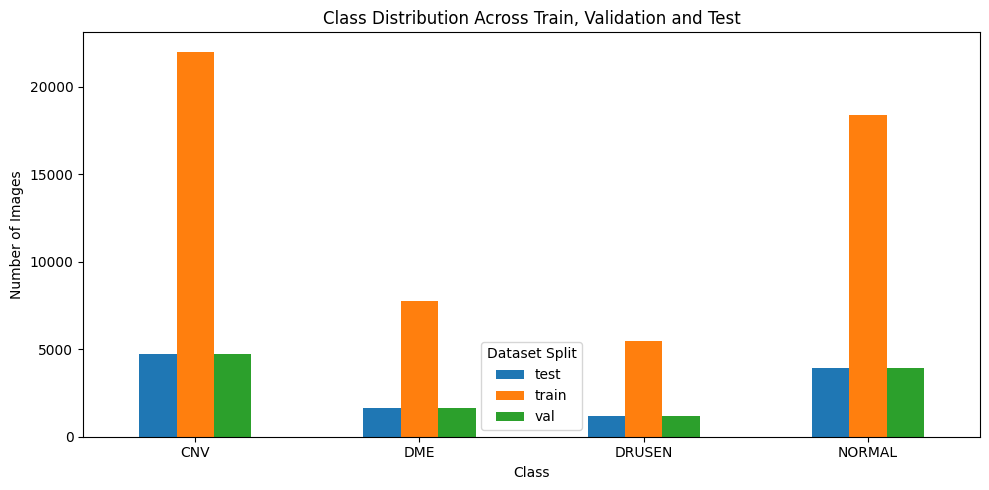

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

class_counts = pd.crosstab(df["label"], df["split"])

print("Class Distribution:")
display(class_counts)

class_counts.plot(kind="bar", figsize=(10, 5))

plt.title("Class Distribution Across Train, Validation and Test")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.legend(title="Dataset Split")
plt.tight_layout()
plt.show()

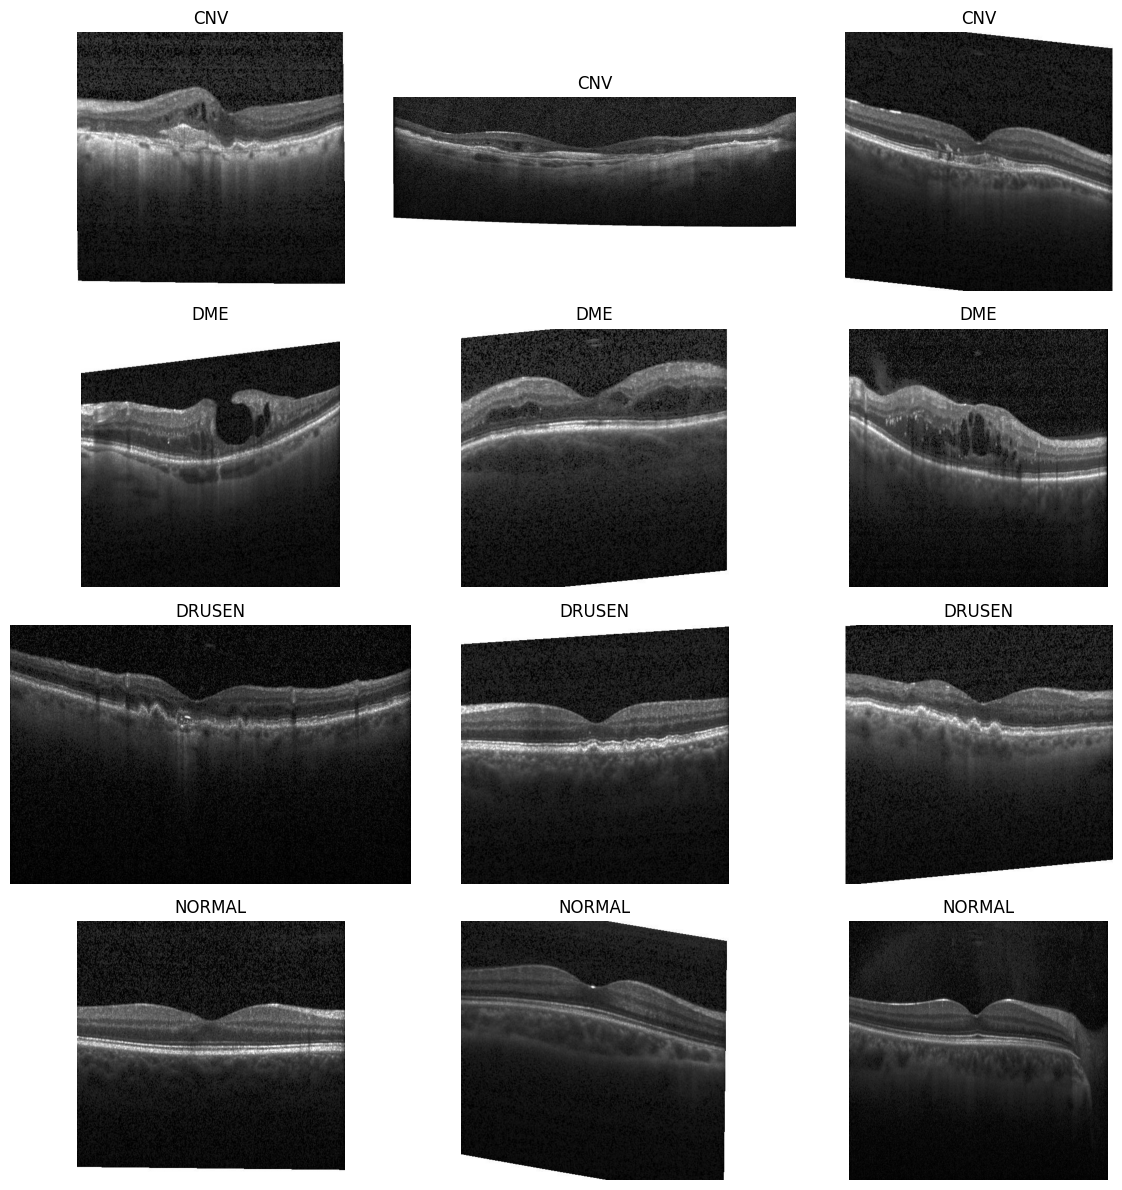

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import random

classes = ["CNV", "DME", "DRUSEN", "NORMAL"]

fig, axes = plt.subplots(4, 3, figsize=(12, 12))

for row, class_name in enumerate(classes):
    samples = df[
        (df["label"] == class_name) &
        (df["split"] == "train")
    ].sample(3, random_state=42)

    for col, (_, sample) in enumerate(samples.iterrows()):
        img_path = image_dir / sample["filepath"]
        img = Image.open(img_path)

        axes[row, col].imshow(img, cmap="gray")
        axes[row, col].set_title(class_name)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

brightness = []
contrast = []

for _, row in df[df["split"] == "train"].sample(100, random_state=42).iterrows():
    img = Image.open(image_dir / row["filepath"]).convert("L")
    img_array = np.array(img)

    brightness.append(img_array.mean())
    contrast.append(img_array.std())

print("Average Brightness:", np.mean(brightness))
print("Average Contrast:", np.mean(contrast))

Average Brightness: 45.44517332630773
Average Contrast: 48.24499624757748


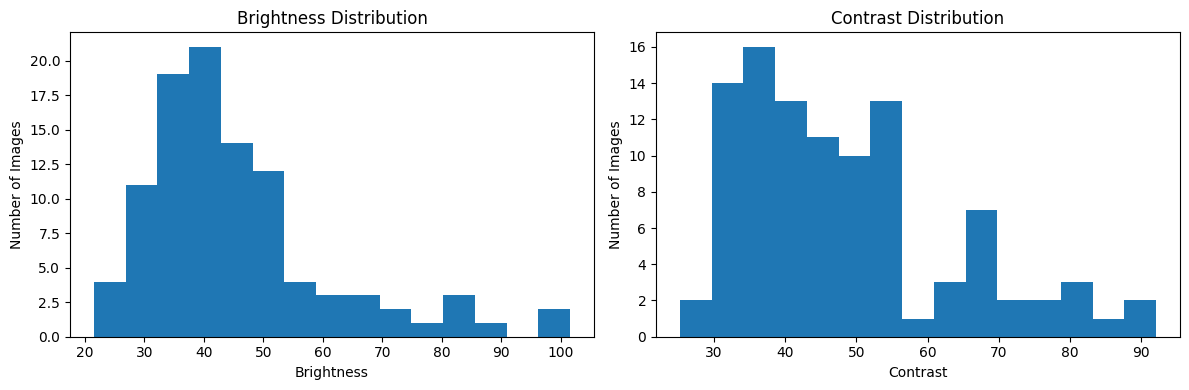

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.hist(brightness, bins=15)
plt.title("Brightness Distribution")
plt.xlabel("Brightness")
plt.ylabel("Number of Images")

plt.subplot(1, 2, 2)
plt.hist(contrast, bins=15)
plt.title("Contrast Distribution")
plt.xlabel("Contrast")
plt.ylabel("Number of Images")

plt.tight_layout()
plt.show()

In [ ]:
from collections import Counter

dimensions = []

sample_images = df[df["split"] == "train"].sample(
    100, random_state=42
)

for _, row in sample_images.iterrows():
    img = Image.open(image_dir / row["filepath"])
    dimensions.append(img.size)

dimension_counts = Counter(dimensions)

print("Most common image dimensions:")
for size, count in dimension_counts.most_common(10):
    print(f"{size}: {count} images")

Most common image dimensions:
(512, 496): 45 images
(768, 496): 27 images
(1536, 496): 15 images
(512, 512): 13 images


In [ ]:
from collections import Counter

image_modes = []

for _, row in df[df["split"] == "train"].sample(100, random_state=42).iterrows():
    img = Image.open(image_dir / row["filepath"])
    image_modes.append(img.mode)

print("Image Modes Distribution:")
print(Counter(image_modes))

Image Modes Distribution:
Counter({'L': 100})


In [ ]:
!ls src

data.py  evaluate.py  models.py  predict.py  train.py


In [ ]:
%cd /content/retinal-oct-classifier

import os

print("Current directory:", os.getcwd())
print("Models folder exists:", os.path.exists("models"))
print("Models folder contents:", os.listdir("models"))

/content/retinal-oct-classifier
Current directory: /content/retinal-oct-classifier
Models folder exists: True
Models folder contents: ['.gitkeep']


In [32]:
!cat src/models.py

In [33]:
with open("src/models.py", "r") as file:
    content = file.read()

print(content)

In [34]:
import os

print("File size:", os.path.getsize("src/models.py"), "bytes")
print("File content:")
!sed -n '1,100p' src/models.py

File size: 0 bytes
File content:


In [35]:
print(open("src/train.py").read())

In [36]:
import os

file_path = "src/train.py"

print("File exists:", os.path.exists(file_path))
print("File size:", os.path.getsize(file_path), "bytes")

with open(file_path, "r") as f:
    content = f.read()

print("Content:", repr(content))

File exists: True
File size: 0 bytes
Content: ''


In [37]:
print(open("src/data.py").read()[:5000])

"""Data loading, cleaning, splitting and preprocessing for the OCT project."""

import argparse
import hashlib
from pathlib import Path

import pandas as pd
import tensorflow as tf
import yaml
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold


def file_hash(path):
    """Return the MD5 fingerprint of a file's bytes."""
    return hashlib.md5(Path(path).read_bytes()).hexdigest()


def index_files(root):
    """Return a table with the relative path, name and hash of every file."""
    root = Path(root)
    if not root.is_dir():
        raise FileNotFoundError(f"Folder not found: {root!r}")
    rows = []
    for path in sorted(root.rglob("*")):
        if path.is_file():
            rows.append({
                "relpath": path.relative_to(root).as_posix(),
                "name": path.name,
                "md5": file_hash(path),
            })
    return pd.DataFrame(rows)


def parse_filename(name):
    """Return (label, patient_id) from CLASS-PATIENTID-IM

In [38]:
with open("src/data.py", "r") as f:
    content = f.read()

print(content[5000:10000])

], "split"] = "test"
        elif number < test_folds + val_folds:
            result.loc[result.index[rows], "split"] = "val"
    return result


def check_no_patient_overlap(table):
    """Stop with an error if a split is empty or two splits share a patient."""
    ids = {name: set(table.loc[table["split"] == name, "patient_id"])
           for name in ["train", "val", "test"]}
    assert all(ids.values()), "A split is empty"
    assert not ids["train"] & ids["val"], "Patients shared by train and val"
    assert not ids["train"] & ids["test"], "Patients shared by train and test"
    assert not ids["val"] & ids["test"], "Patients shared by val and test"


def print_split_summary(table):
    """Print images, class percentages and patients for each split."""
    order = ["train", "val", "test"]
    images = pd.crosstab(table["label"], table["split"])[order]
    print("Images per class:\n", images)
    print("Class % inside each split:\n",
          (images / images.sum() * 100).round(2)

In [40]:
print(content[10000:15000])

    if training:
        table = table.sample(frac=1, random_state=seed)
    root = Path(config["dataset"]["image_dir"])
    paths = [str(root / path) for path in table["filepath"]]
    indices = [names.index(label) for label in table["label"]]
    labels = tf.one_hot(indices, len(names))

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    dataset = dataset.map(
        lambda path, label: (load_image(path, size), label),
        num_parallel_calls=tf.data.AUTOTUNE)
    if settings["cache"]:
        dataset = dataset.cache()
    if training:
        dataset = dataset.shuffle(settings["shuffle_buffer"], seed=seed)
    dataset = dataset.batch(settings["batch_size"])
    if training and config["augmentation"]["enabled"]:
        layers = build_augmentation(config["augmentation"], seed)
        dataset = dataset.map(
            lambda images, labels: (augment_batch(images, layers), labels))
    dataset = dataset.map(
        lambda images, labels: (prepare_image(images,

In [41]:
from src.data import get_datasets

In [42]:
%cd /content/retinal-oct-classifier

/content/retinal-oct-classifier


In [43]:
from src.data import get_datasets

In [44]:
import yaml
from src.data import get_datasets

with open("configs/data.yaml") as f:
    config = yaml.safe_load(f)

train_ds, val_ds, test_ds, class_names, class_weights = get_datasets(config)

print("Classes:", class_names)
print("Class weights:", class_weights)

Classes: ['CNV', 'DME', 'DRUSEN', 'NORMAL']
Class weights: {0: 0.6096987459105779, 1: 1.7244891402133402, 2: 2.4476924480116744, 3: 0.7291734594065863}


In [45]:
for images, labels in train_ds.take(1):
    print("Images shape:", images.shape)
    print("Labels shape:", labels.shape)
    print("Image data type:", images.dtype)

Images shape: (32, 224, 224, 3)
Labels shape: (32, 4)
Image data type: <dtype: 'float32'>


In [46]:
train_labels = df[df["split"] == "train"]["label"]

print("Majority Class:", train_labels.mode()[0])
print("Majority Class Accuracy:",
      train_labels.value_counts(normalize=True).max())

Majority Class: CNV
Majority Class Accuracy: 0.4100385668772008


In [47]:
test_labels = df[df["split"] == "test"]["label"]

majority_class = train_labels.mode()[0]

baseline_accuracy = (test_labels == majority_class).mean()

print("Majority Class:", majority_class)
print("Test Baseline Accuracy:", baseline_accuracy)

Majority Class: CNV
Test Baseline Accuracy: 0.41001564945226915


In [48]:
from src.data import load_splits, make_dataset

# Load the official team splits
table = load_splits(config["split"]["splits_csv"])

# Separate training and validation data
train_table = table[table["split"] == "train"]
val_table = table[table["split"] == "val"]

# Create datasets without augmentation
train_baseline_ds = make_dataset(train_table, config, training=False)
val_baseline_ds = make_dataset(val_table, config, training=False)

print("Train images:", len(train_table))
print("Validation images:", len(val_table))

Train images: 53673
Validation images: 11502


In [49]:
import copy

baseline_config = copy.deepcopy(config)
baseline_config["pipeline"]["cache"] = False

train_baseline_ds = make_dataset(
    train_table, baseline_config, training=False
)

val_baseline_ds = make_dataset(
    val_table, baseline_config, training=False
)

for images, labels in train_baseline_ds.take(1):
    print("Image shape:", images.shape)
    print("Label shape:", labels.shape)

Image shape: (32, 224, 224, 3)
Label shape: (32, 4)


In [53]:
# Use a small sample for baseline development
train_small = train_table.sample(
    n=5000, random_state=42
)

val_small = val_table.sample(
    n=1000, random_state=42
)

print("Training sample:", len(train_small))
print("Validation sample:", len(val_small))

Training sample: 5000
Validation sample: 1000


In [54]:
train_small_ds = make_dataset(
    train_small, baseline_config, training=False
)

val_small_ds = make_dataset(
    val_small, baseline_config, training=False
)

In [56]:
X_train, y_train = dataset_to_features(train_small_ds)
X_val, y_val = dataset_to_features(val_small_ds)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

X_train: (5000, 256)
y_train: (5000,)
X_val: (1000, 256)
y_val: (1000,)


In [57]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Create the model
logistic_model = LogisticRegression(
    max_iter=300,
    random_state=42
)

# Train
logistic_model.fit(X_train, y_train)

# Predict validation labels
y_val_pred = logistic_model.predict(X_val)

# Evaluate
print("Validation Accuracy:",
      accuracy_score(y_val, y_val_pred))

print("Validation Macro F1:",
      f1_score(y_val, y_val_pred, average="macro"))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred,
    target_names=class_names
))

Validation Accuracy: 0.506
Validation Macro F1: 0.3077429408544149

Classification Report:
              precision    recall  f1-score   support

         CNV       0.53      0.71      0.61       413
         DME       0.26      0.04      0.06       140
      DRUSEN       0.11      0.01      0.02       105
      NORMAL       0.50      0.60      0.54       342

    accuracy                           0.51      1000
   macro avg       0.35      0.34      0.31      1000
weighted avg       0.44      0.51      0.45      1000



In [58]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

balanced_model = LogisticRegression(
    max_iter=300,
    random_state=42,
    class_weight="balanced"
)

balanced_model.fit(X_train, y_train)

y_val_balanced = balanced_model.predict(X_val)

print("Balanced Accuracy:",
      accuracy_score(y_val, y_val_balanced))

print("Balanced Macro F1:",
      f1_score(y_val, y_val_balanced, average="macro"))

print(classification_report(
    y_val,
    y_val_balanced,
    target_names=class_names
))

Balanced Accuracy: 0.378
Balanced Macro F1: 0.3365975740463013
              precision    recall  f1-score   support

         CNV       0.62      0.42      0.50       413
         DME       0.21      0.36      0.27       140
      DRUSEN       0.11      0.23      0.15       105
      NORMAL       0.50      0.37      0.43       342

    accuracy                           0.38      1000
   macro avg       0.36      0.35      0.34      1000
weighted avg       0.47      0.38      0.41      1000



In [59]:
from sklearn.metrics import balanced_accuracy_score

print(
    "True Balanced Accuracy:",
    balanced_accuracy_score(y_val, y_val_balanced)
)

True Balanced Accuracy: 0.34771374056610455
